In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

STUDENT_ID = 20244080126

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]    {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]  {RUN_ID}")

[Conda 环境] exp01
[学号]    20244080126
[机器指纹] 759a8a296917ae29
[RUN_ID]  20244080126-759a8a296917ae29


In [2]:
# 实验一 创建不同类型数组
arr_int = np.array([1,2,3,4])
arr_float = np.array([1.1, 2.2, 3.3])
arr_bool = np.array([True, False, True])

print("===== 整数数组 =====")
print("data:", arr_int)
print("dtype:", arr_int.dtype, " shape:", arr_int.shape, " ndim:", arr_int.ndim)
print("===== 浮点数组 =====")
print("data:", arr_float)
print("dtype:", arr_float.dtype, " shape:", arr_float.shape, " ndim:", arr_float.ndim)
print("===== 布尔数组 =====")
print("data:", arr_bool)
print("dtype:", arr_bool.dtype, " shape:", arr_bool.shape, " ndim:", arr_bool.ndim)


===== 整数数组 =====
data: [1 2 3 4]
dtype: int64  shape: (4,)  ndim: 1
===== 浮点数组 =====
data: [1.1 2.2 3.3]
dtype: float64  shape: (3,)  ndim: 1
===== 布尔数组 =====
data: [ True False  True]
dtype: bool  shape: (3,)  ndim: 1


In [3]:
#reshape改变形状
arr = np.arange(12)
print("原始一维数组：", arr)

arr34 = arr.reshape(3,4)
print("\nreshape(3,4):\n", arr34)

arr232 = arr.reshape(2,3,2)
print("\nreshape(2,3,2):\n", arr232)


原始一维数组： [ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


In [4]:
#数组索引
a = np.arange(12).reshape(3,4)
print("原始数组 a:\n", a)

row2 = a[1, :]
print("\n取第2行（下标1）：", row2, " shape:", row2.shape)

col1_3 = a[:, 0:3]
print("\n取1~3列（下标0,1,2）：\n", col1_3, " shape:", col1_3.shape)

gt6 = a[a>6]
print("\n大于6的元素：", gt6, " shape:", gt6.shape)


原始数组 a:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

取第2行（下标1）： [4 5 6 7]  shape: (4,)

取1~3列（下标0,1,2）：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]  shape: (3, 3)

大于6的元素： [ 7  8  9 10 11]  shape: (5,)


In [5]:
#布尔索引
x = np.arange(10)
print("原始x：", x)

# 小于2 或者 大于7
res1 = x[(x<2) | (x>7)]
res1_2 = x[np.logical_or(x<2, x>7)]
print("\n小于2或大于7：", res1, " logical_or版本：", res1_2)

# 大于3 并且 小于7
res2 = x[(x>3) & (x<7)]
res2_2 = x[np.logical_and(x>3, x<7)]
print("大于3且小于7：", res2, " logical_and版本：", res2_2)


原始x： [0 1 2 3 4 5 6 7 8 9]

小于2或大于7： [0 1 8 9]  logical_or版本： [0 1 8 9]
大于3且小于7： [4 5 6]  logical_and版本： [4 5 6]


In [6]:
#逐元素乘，矩阵乘法
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])
print("A:\n",A,"\nB:\n",B)

elem_mul = A * B
mat_mul = A @ B
mat_mul2 = np.matmul(A,B)
print("\n逐元素相乘 A*B：\n", elem_mul)
print("\n矩阵乘法 A@B：\n", mat_mul)
print("\nnp.matmul(A,B):\n", mat_mul2)


A:
 [[1 2]
 [3 4]] 
B:
 [[5 6]
 [7 8]]

逐元素相乘 A*B：
 [[ 5 12]
 [21 32]]

矩阵乘法 A@B：
 [[19 22]
 [43 50]]

np.matmul(A,B):
 [[19 22]
 [43 50]]


In [7]:
#实验二 生成1000个正态成绩，clip限制0~100
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
print("样本数：", len(scores))
print("最小值：", np.min(scores))
print("最大值：", np.max(scores))
print("均值：", np.mean(scores))
print("标准差：", np.std(scores))
print("极差：", np.max(scores)-np.min(scores))


样本数： 1000
最小值： 37.53214369608624
最大值： 100.0
均值： 69.54255759157287
标准差： 10.057826194806282
极差： 62.46785630391376


In [8]:
#不放回抽样：均匀抽样 加权抽样
pool = np.arange(1,11)
# 均匀等概率不放回抽5个
sample_equal = np.random.choice(pool, size=5, replace=False)
# 权重和数字成正比加权抽样
p_weight = pool / pool.sum()
sample_weighted = np.random.choice(pool, size=5, replace=False, p=p_weight)
print("均匀抽样：", sample_equal)
print("按数值大小加权抽样：", sample_weighted)


均匀抽样： [3 1 6 2 7]
按数值大小加权抽样： [ 7  9  6  5 10]


In [9]:
#随机排列：不修改原数组/原地打乱
arr_ori = np.arange(6)
arr_copy = arr_ori.copy()
# permutation 返回新数组，原数组不变
shuffle_new = np.random.permutation(arr_ori)
print("原始数组：", arr_ori)
print("permutation得到新打乱数组：", shuffle_new)
print("permutation后原数组没变：", arr_ori)
# shuffle原地修改原数组
np.random.shuffle(arr_copy)
print("\nshuffle原地打乱后数组：", arr_copy)


原始数组： [0 1 2 3 4 5]
permutation得到新打乱数组： [0 5 1 4 2 3]
permutation后原数组没变： [0 1 2 3 4 5]

shuffle原地打乱后数组： [2 0 3 5 4 1]


In [10]:
#插入nan缺失值，对比均值
s = np.copy(scores[:50])
s[[9,19,29]] = np.nan
nan_cnt = np.sum(np.isnan(s))
mean_all = np.mean(s)
mean_nan_skip = np.nanmean(s)
print("缺失值数量：", nan_cnt)
print("直接mean（含nan）：", mean_all)
print("nanmean忽略缺失值：", mean_nan_skip)


缺失值数量： 3
直接mean（含nan）： nan
nanmean忽略缺失值： 69.8704184145842


In [11]:
#转为内存表格
df_score = pd.DataFrame({
    "index": np.arange(len(s)),
    "score": s
})
df_score.head()


,index,score
0,0,78.246897
1,1,63.422209
2,2,89.063916
3,3,57.031657
4,4,80.748075


In [12]:
#实验三 
from scipy.linalg import solve
from scipy.optimize import root, minimize
from scipy.stats import ttest_ind

In [13]:
#解线性方程组
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
x_sol = solve(A,b)
print("解 x,y：", x_sol)
# 代入验证
print("验证 3x+y = ", 3*x_sol[0]+x_sol[1])
print("验证 x+2y = ", x_sol[0]+2*x_sol[1])


解 x,y： [2. 3.]
验证 3x+y =  9.0
验证 x+2y =  8.0


In [14]:
#求根
def f(x):
    return x**2 - 2
# 正根猜测 1.5
sol_pos = root(f, x0=1.5)
# 负根猜测 -1.5
sol_neg = root(f, x0=-1.5)
print("正根结果：", sol_pos.x, "成功：", sol_pos.success, "f值：", f(sol_pos.x))
print("负根结果：", sol_neg.x, "成功：", sol_neg.success, "f值：", f(sol_neg.x))


正根结果： [1.41421356] 成功： True f值： [4.4408921e-16]
负根结果： [-1.41421356] 成功： True f值： [4.4408921e-16]


In [15]:
#求最小值
def f2(x):
    return x**2 + x + 2
res_min = minimize(f2, x0=0)
print("极小点x：", res_min.x)
print("极小函数值：", res_min.fun)
# 解析解：顶点 x=-0.5, f=1.75
print("解析解：x=-0.5, f=(-0.5)^2-0.5+2 = 1.75")


极小点x： [-0.50000001]
极小函数值： 1.75
解析解：x=-0.5, f=(-0.5)^2-0.5+2 = 1.75


In [16]:
#独立样本t检验
np.random.seed(42)
g1 = np.random.normal(loc=0, scale=1, size=100)
g2 = np.random.normal(loc=1, scale=1, size=100)
t_stat, p_val = ttest_ind(g1, g2)
print("t统计量：", t_stat)
print("p值：", p_val)
alpha = 0.05
if p_val < alpha:
    print(f"p<{alpha}，拒绝原假设，两组均值有显著差异")
else:
    print(f"p≥{alpha}，不能拒绝原假设，无显著差异")


t统计量： -8.55145994324873
p值： 3.2929614287036995e-15
p<0.05，拒绝原假设，两组均值有显著差异


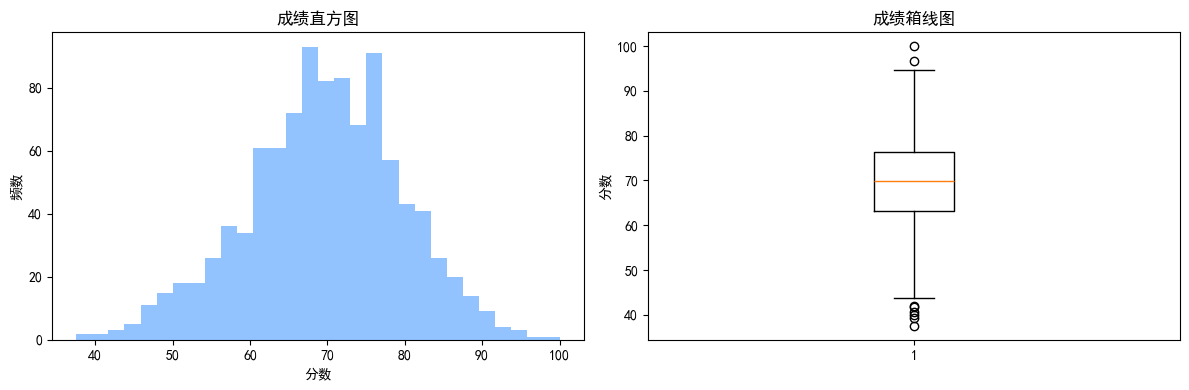

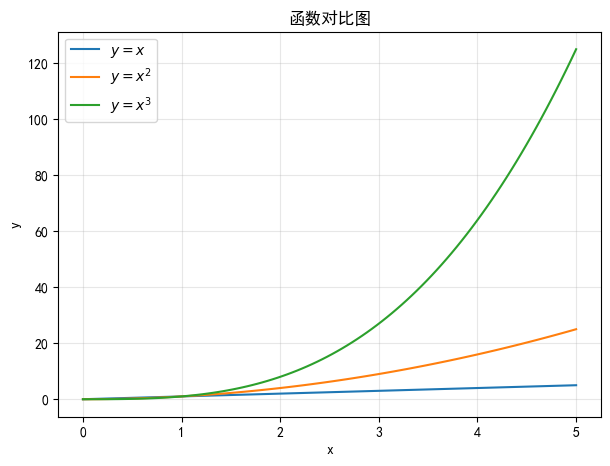

In [17]:
#绘图
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].hist(scores, bins=30, color="#66aaff", alpha=0.7)
axes[0].set_title("成绩直方图")
axes[0].set_xlabel("分数")
axes[0].set_ylabel("频数")

axes[1].boxplot(scores)
axes[1].set_title("成绩箱线图")
axes[1].set_ylabel("分数")
plt.tight_layout()
plt.show()

# y=x, y=x², y=x³ 0~5
x_line = np.linspace(0,5,100)
y1 = x_line
y2 = x_line**2
y3 = x_line**3
plt.figure(figsize=(7,5))
plt.plot(x_line, y1, label="$y=x$")
plt.plot(x_line, y2, label="$y=x^2$")
plt.plot(x_line, y3, label="$y=x^3$")
plt.title("函数对比图")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [18]:
#实验四
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name")
# 新增总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n基本统计信息：")
print(df.describe())


行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [19]:
#loc，iloc读取Carol，筛选平均分>=80
# loc按索引名
carol_loc = df.loc["Carol"]
# iloc按位置下标，Carol是第2行（下标1）
carol_iloc = df.iloc[1]
print("loc取Carol：\n", carol_loc)
print("\niloc取Carol：\n", carol_iloc)

high_avg = df[df["Average"] >= 80]
print("\n平均分不低于80的学生：\n", high_avg)


loc取Carol：
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc取Carol：
 Group              A
Math              72
English           68
Python            80
Total            220
Average    73.333333
Name: Bob, dtype: object

平均分不低于80的学生：
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [20]:
#axis=0列均值/axis=1行均值
col_mean = df[["Math","English","Python"]].mean(axis=0)
row_mean = df[["Math","English","Python"]].mean(axis=1)
print("各科列均值(axis=0)：\n", col_mean)
print("\n每个学生行均值(axis=1)：\n", row_mean)


各科列均值(axis=0)：
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每个学生行均值(axis=1)：
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [21]:
#apply最高分，agg聚合，rank排名
df["MaxScore"] = df[["Math","English","Python"]].apply(max, axis=1)
agg_res = df[["Math","English","Python"]].agg(["min","mean","max"])
# Math列排名，降序
df["Math_Rank"] = df["Math"].rank(ascending=False, method="min")
print("新增最高分列：\n", df[["MaxScore"]])
print("\n各科min/mean/max：\n", agg_res)
print("\n带排名：\n", df[["Math","Math_Rank"]])


新增最高分列：
        MaxScore
Name           
Alice        95
Bob          80
Carol        91
David        73
Eva          92
Frank        84

各科min/mean/max：
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

带排名：
        Math  Math_Rank
Name                  
Alice    88        2.0
Bob      72        5.0
Carol    91        1.0
David    65        6.0
Eva      79        4.0
Frank    84        3.0


In [22]:
#分组统计+transform组均值
group_stat = df.groupby("Group").agg(人数=("Average","count"), 组均分=("Average","mean"))
# transform，给每行增加同组Python平均分
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("分组统计：\n", group_stat)
print("\n增加组Python均值列：\n", df[["Group","Python","Group_Python_Mean"]])


分组统计：
        人数        组均分
Group               
A       3  83.333333
B       3  79.555556

增加组Python均值列：
       Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


In [23]:
#filter筛选组
def filter_func(subdf):
    return subdf["Python"].mean() >= 80
df_filtered = df.groupby("Group").filter(filter_func)
print("Python组均分≥80的组及学生：\n", df_filtered)


Python组均分≥80的组及学生：
       Group  Math  English  Python  Total    Average  MaxScore  Math_Rank  \
Name                                                                        
Alice     A    88       90      95    273  91.000000        95        2.0   
Bob       A    72       68      80    220  73.333333        80        5.0   
Carol     B    91       85      89    265  88.333333        91        1.0   
David     B    65       73      70    208  69.333333        73        6.0   
Eva       A    79       92      86    257  85.666667        92        4.0   
Frank     B    84       77      82    243  81.000000        84        3.0   

       Group_Python_Mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  


In [24]:
#协方差矩阵，皮尔逊相关矩阵
sub = df[["Math","English","Python"]]
cov_mat = sub.cov()
corr_mat = sub.corr()
print("协方差矩阵：\n", cov_mat)
print("\n皮尔逊相关矩阵：\n", corr_mat)
# 举例：Math和Python相关系数
print("\n举例：Math与Python的相关系数：", corr_mat.loc["Math","Python"])


协方差矩阵：
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔逊相关矩阵：
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000

举例：Math与Python的相关系数： 0.8847760993538873
